In [2]:
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

c:\Users\Barış\Desktop\YAZILIM\tfidf-turkish-analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
ds = load_dataset("maydogan/Turkish_SentimentAnalysis_TRSAv1")
ds

DatasetDict({
    train: Dataset({
        features: ['id', 'score', 'review'],
        num_rows: 150000
    })
})

In [4]:
list(ds.keys())

['train']

In [5]:
split_name = next(iter(ds.keys()))
raw_df = ds[split_name].to_pandas()

In [6]:
raw_df.head(10)

,id,score,review
0,0,Positive,Kokusu çok güzel etkisi de efsane
1,1,Negative,hiç bir fark olmadı siyah nokta silmedi
2,2,Positive,şeffaf güzel bir krem elimi yumuşacık yaptı
3,3,Positive,Özellikle karma ve hassas cildiniz varsa La Ro...
4,4,Negative,çok iyi nemlendiriyor ama daha ucuz muadilleri...
5,5,Neutral,Ürün fena değil güzel tabi öbür kimyasallar gi...
6,6,Negative,şampuan çok köttü
7,7,Negative,Ürün kullanıp memnun olduğum bir ürün fakat şi...
8,8,Neutral,yeni kullaniyorum dokulmeleri azaltır inşallah
9,9,Positive,Kesinlikle saçlarınızda sarı işlem barsa hafta...


In [7]:
label_column = "score"
text_column = "review"

normalized_df = raw_df.copy()
normalized_df[text_column] = normalized_df[text_column].astype("string").str.strip()
review_label_counts = normalized_df.groupby(text_column)[label_column].nunique()
conflicting_texts = review_label_counts[review_label_counts.gt(1)].index
conflicting_reviews_df = normalized_df.loc[normalized_df[text_column].isin(conflicting_texts)].copy()

data_quality = pd.Series({
    "row_count": len(raw_df),
    "missing_text": raw_df[text_column].isna().sum(),
    "blank_text": normalized_df[text_column].eq("").sum(),
    "missing_label": raw_df[label_column].isna().sum(),
    "duplicate_review_rows": normalized_df.duplicated(subset=[text_column]).sum(),
    "duplicate_review_label_rows": normalized_df.duplicated(subset=[text_column, label_column]).sum(),
    "conflicting_review_groups": len(conflicting_texts),
    "conflicting_review_rows": normalized_df[text_column].isin(conflicting_texts).sum(),
    "whitespace_edges": raw_df[text_column].astype("string").ne(normalized_df[text_column]).sum()
})

data_quality

row_count                      150000
missing_text                        0
blank_text                          0
missing_label                       0
duplicate_review_rows            9046
duplicate_review_label_rows      8067
conflicting_review_groups         891
conflicting_review_rows          6883
whitespace_edges                  366
dtype: int64

In [9]:
conflicting_reviews_summary = pd.Series({
    "conflicting_text_groups": conflicting_reviews_df[text_column].nunique(),
    "conflicting_rows": len(conflicting_reviews_df),
    "unique_text_label_pairs": conflicting_reviews_df[[text_column, label_column]].drop_duplicates().shape[0]
})

conflicting_reviews_summary

conflicting_text_groups     891
conflicting_rows           6883
unique_text_label_pairs    1870
dtype: int64

In [10]:
label_counts = raw_df[label_column].value_counts(dropna=False)
label_counts

score
Positive    50000
Negative    50000
Neutral     50000
Name: count, dtype: int64

In [11]:
text_metrics_df = normalized_df.assign(
    character_count=normalized_df[text_column].str.len(),
    word_count=normalized_df[text_column].str.split().str.len()
)

text_metrics_df.groupby(label_column)[["character_count", "word_count"]].describe()

character_count                                                       \
                   count      mean        std  min   25%   50%    75%     max   
score                                                                           
Negative         50000.0  77.13818  69.703052  3.0  31.0  56.0  100.0  1458.0   
Neutral          50000.0  74.54372  70.029772  3.0  30.0  54.0   96.0  1993.0   
Positive         50000.0  92.91224  76.959919  5.0  45.0  71.0  117.0  1433.0   

         word_count                                                    
              count      mean        std  min  25%   50%   75%    max  
score                                                                  
Negative    50000.0  11.46540  10.114515  1.0  5.0   8.0  15.0  209.0  
Neutral     50000.0  10.99108   9.961529  1.0  5.0   8.0  14.0  283.0  
Positive    50000.0  13.36694  10.837566  1.0  7.0  10.0  17.0  207.0

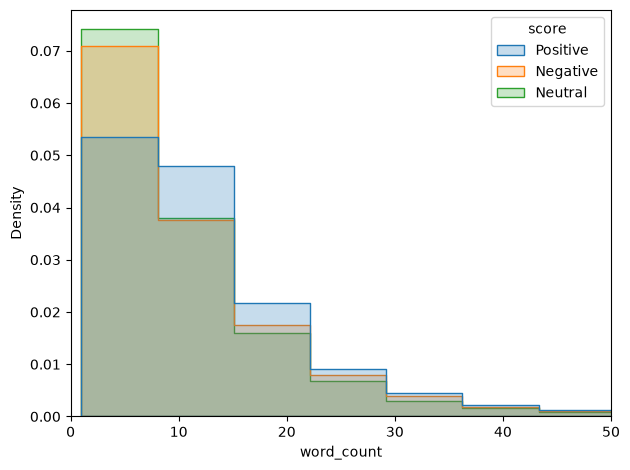

In [12]:
sns.histplot(
    data=text_metrics_df,
    x="word_count",
    hue=label_column,
    bins=40,
    element="step",
    stat="density",
    common_norm=False
)
plt.xlim(0, text_metrics_df["word_count"].quantile(0.99))
plt.tight_layout()
plt.show()

In [13]:
conflicting_reviews_df.loc[
    :,
    [text_column, label_column]
].sort_values(text_column).head(20)

,review,score
26559,Abartıldığı kadar güzel olduğunu düşünmüyorum,Neutral
35836,Abartıldığı kadar güzel olduğunu düşünmüyorum,Negative
12967,Alınabilir,Neutral
43788,Alınabilir,Neutral
45899,Alınabilir,Negative
50358,Alınabilir,Neutral
58969,Alınabilir,Neutral
60016,Alınabilir,Neutral
73049,Alınabilir,Neutral
89950,Alınabilir,Neutral


In [14]:
cleaned_df = raw_df.dropna(subset=[text_column, label_column]).copy()
cleaned_df[text_column] = cleaned_df[text_column].astype("string").str.strip()
cleaned_df = cleaned_df.loc[cleaned_df[text_column].ne("")].copy()

cleaned_review_label_counts = cleaned_df.groupby(text_column)[label_column].nunique()
conflicting_texts = cleaned_review_label_counts[cleaned_review_label_counts.gt(1)].index
conflicting_rows_removed = len(conflicting_reviews_df)
cleaned_df = cleaned_df.loc[~cleaned_df[text_column].isin(conflicting_texts)].copy()

rows_before_deduplication = len(cleaned_df)
cleaned_df = cleaned_df.drop_duplicates(subset=[text_column, label_column]).reset_index(drop=True)
duplicate_rows_removed = rows_before_deduplication - len(cleaned_df)

cleaning_summary = pd.Series({
    "rows_before_cleaning": len(raw_df),
    "rows_after_cleaning": len(cleaned_df),
    "conflicting_text_groups_removed": len(conflicting_texts),
    "conflicting_rows_removed": conflicting_rows_removed,
    "duplicate_rows_removed": duplicate_rows_removed
})

cleaning_summary

rows_before_cleaning               150000
rows_after_cleaning                140063
conflicting_text_groups_removed       891
conflicting_rows_removed             6883
duplicate_rows_removed               3054
dtype: int64

In [15]:
cleaned_df[label_column].value_counts()

score
Positive    48240
Negative    46433
Neutral     45390
Name: count, dtype: int64

In [17]:
from sklearn.model_selection import train_test_split

train_df, temporary_df = train_test_split(
    cleaned_df,
    test_size=0.30,
    random_state=42,
    stratify=cleaned_df[label_column]

)

validation_df, test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    random_state=42,
    stratify=temporary_df[label_column]
)

In [18]:
pd.DataFrame({
    "train": train_df[label_column].value_counts(normalize=True),
    "validation": validation_df[label_column].value_counts(normalize=True),
    "test": test_df[label_column].value_counts(normalize=True)
}).round(4)

,train,validation,test
score,,,
Positive,0.3444,0.3444,0.3444
Negative,0.3315,0.3315,0.3315
Neutral,0.3241,0.3241,0.3241


In [19]:
X_train = train_df[text_column]
y_train = train_df[label_column]
X_validation = validation_df[text_column]
y_validation = validation_df[label_column]

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

baseline_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

In [21]:
baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Negative','Neutral','Positive']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


In [22]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

validation_predictions = baseline_model.predict(X_validation)
validation_report = classification_report(
    y_validation,
    validation_predictions,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(validation_report).transpose()

,precision,recall,f1-score,support
Negative,0.860123,0.822828,0.841063,6965.00000
Neutral,0.723927,0.713719,0.718787,6808.00000
Positive,0.819885,0.864981,0.841829,7236.00000
accuracy,0.801990,0.801990,0.801990,0.80199
macro avg,0.801312,0.800509,0.800560,21009.00000
weighted avg,0.802130,0.801990,0.801703,21009.00000


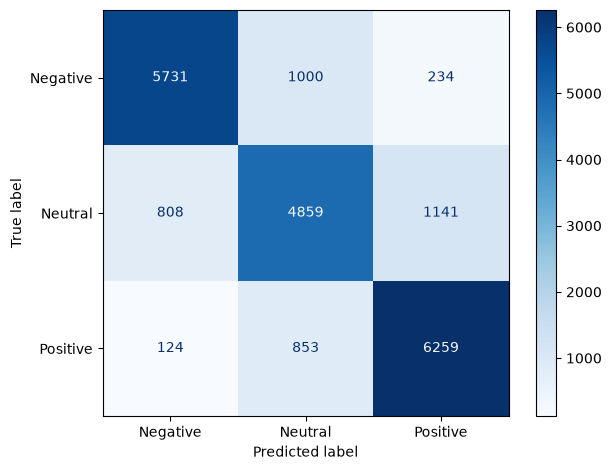

In [23]:
ConfusionMatrixDisplay.from_predictions(
    y_validation,
    validation_predictions,
    labels=["Negative", "Neutral", "Positive"],
    cmap="Blues"
)
plt.tight_layout()
plt.show()

In [26]:
from pathlib import Path
import joblib

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

model_directory = project_root / "models"
model_directory.mkdir(exist_ok=True)
model_path = model_directory / "tfidf_v0.1.joblib"
joblib.dump(baseline_model, model_path)
model_path

WindowsPath('c:/Users/Barış/Desktop/YAZILIM/tfidf-turkish-analysis/models/tfidf_v0.1.joblib')